# Lab Assignment 04: Image Denoising Using Autoencoders
**Course**: Machine Learning Projects with Python (CSE 4192)  
**Objective**: Implement, train, evaluate, and compare 5 distinct Autoencoder architectures on the MNIST handwritten digit dataset corrupted by additive Gaussian noise.

### Models Implemented:
1. **Undercomplete Autoencoder** (Latent dimension = 32, MSE loss)
2. **Sparse Autoencoder** (Latent dimension = 32, $L_1$ activity regularization = $10^{-5}$, MSE loss)
3. **Denoising Autoencoder** (Latent dimension = 64, MSE loss)
4. **Convolutional Autoencoder** (Conv2D/MaxPool/UpSampling, Binary Cross-Entropy loss)
5. **Contractive Autoencoder** (Sigmoid latent layer, Contractive penalty weight = $10^{-4}$)

---

## Step 1: Environment Setup & Library Imports

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from skimage.metrics import structural_similarity as ssim_fn
import tensorflow as tf
from tensorflow.keras import layers, regularizers, Model
from tensorflow.keras.datasets import mnist

# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

print(f"TensorFlow Version: {tf.__version__}")
gpus = tf.config.list_physical_devices('GPU')
print(f"Available GPUs: {len(gpus)} -> {gpus}")

TensorFlow Version: 2.21.0
Available GPUs: 1 -> [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## Step 2 & 3: Load & Preprocess MNIST Dataset
The dataset contains 60,000 training images and 10,000 test images ($28 \times 28$ pixels). Pixels are normalized from $[0, 255]$ to $[0.0, 1.0]$.

In [2]:
(x_train_raw, y_train), (x_test_raw, y_test) = mnist.load_data()

# Normalize to [0.0, 1.0]
x_train_clean = x_train_raw.astype('float32') / 255.0
x_test_clean = x_test_raw.astype('float32') / 255.0

# Reserve 10% of training set for validation (54,000 train, 6,000 val)
num_train = int(len(x_train_clean) * 0.9)
x_val_clean = x_train_clean[num_train:]
x_train_clean = x_train_clean[:num_train]

print(f"Clean Training shape:   {x_train_clean.shape}")
print(f"Clean Validation shape: {x_val_clean.shape}")
print(f"Clean Test shape:       {x_test_clean.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Clean Training shape:   (54000, 28, 28)
Clean Validation shape: (6000, 28, 28)
Clean Test shape:       (10000, 28, 28)


## Step 4: Noise Injection
We inject zero-mean additive Gaussian noise with standard deviation $\sigma = 0.3$ and clip the pixels to $[0.0, 1.0]$.

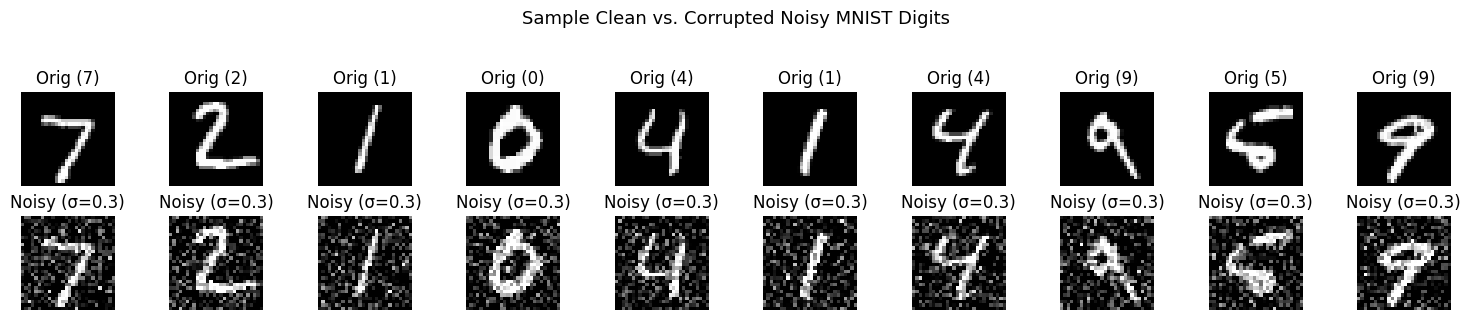

In [3]:
def add_gaussian_noise(images, noise_factor=0.3, seed=None):
    if seed is not None:
        np.random.seed(seed)
    noisy = images + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=images.shape)
    return np.clip(noisy, 0.0, 1.0).astype('float32')

x_train_noisy = add_gaussian_noise(x_train_clean, noise_factor=0.3, seed=42)
x_val_noisy   = add_gaussian_noise(x_val_clean, noise_factor=0.3, seed=43)
x_test_noisy  = add_gaussian_noise(x_test_clean, noise_factor=0.3, seed=44)

# Display 10 original vs noisy samples
plt.figure(figsize=(15, 3))
for i in range(10):
    # Original
    ax = plt.subplot(2, 10, i + 1)
    plt.imshow(x_test_clean[i], cmap='gray')
    plt.title(f"Orig ({y_test[i]})")
    plt.axis('off')
    # Noisy
    ax = plt.subplot(2, 10, i + 11)
    plt.imshow(x_test_noisy[i], cmap='gray')
    plt.title("Noisy (σ=0.3)")
    plt.axis('off')
plt.suptitle("Sample Clean vs. Corrupted Noisy MNIST Digits", fontsize=13, y=1.05)
plt.tight_layout()
plt.show()

## Step 5: Data Layout Preparation (Dense & Convolutional Tensors)
- Dense Autoencoders require flattened vectors of shape $(N, 784)$.
- Convolutional Autoencoders require image tensors of shape $(N, 28, 28, 1)$.

In [4]:
# Flattened representations for Dense Autoencoders
x_train_clean_flat = x_train_clean.reshape(-1, 784)
x_train_noisy_flat = x_train_noisy.reshape(-1, 784)
x_val_clean_flat   = x_val_clean.reshape(-1, 784)
x_val_noisy_flat   = x_val_noisy.reshape(-1, 784)
x_test_clean_flat  = x_test_clean.reshape(-1, 784)
x_test_noisy_flat  = x_test_noisy.reshape(-1, 784)

# Spatial representations for Convolutional Autoencoder
x_train_clean_conv = np.expand_dims(x_train_clean, axis=-1)
x_train_noisy_conv = np.expand_dims(x_train_noisy, axis=-1)
x_val_clean_conv   = np.expand_dims(x_val_clean, axis=-1)
x_val_noisy_conv   = np.expand_dims(x_val_noisy, axis=-1)
x_test_clean_conv  = np.expand_dims(x_test_clean, axis=-1)
x_test_noisy_conv  = np.expand_dims(x_test_noisy, axis=-1)

print("Data layouts prepared successfully!")

Data layouts prepared successfully!


## Step 6: Architecture Definitions for the 5 Autoencoders

In [5]:
# 1. Undercomplete Autoencoder (Bottleneck: 32 units)
def build_undercomplete_ae():
    inputs = layers.Input(shape=(784,), name='input')
    x = layers.Dense(256, activation='relu')(inputs)
    x = layers.Dense(128, activation='relu')(x)
    latent = layers.Dense(32, activation='relu', name='latent')(x)
    x = layers.Dense(128, activation='relu')(latent)
    x = layers.Dense(256, activation='relu')(x)
    outputs = layers.Dense(784, activation='sigmoid')(x)
    model = Model(inputs, outputs, name='Undercomplete_AE')
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
    return model

# 2. Sparse Autoencoder (Bottleneck: 32 units with L1 penalty 1e-5)
def build_sparse_ae():
    inputs = layers.Input(shape=(784,), name='input')
    x = layers.Dense(256, activation='relu')(inputs)
    x = layers.Dense(128, activation='relu')(x)
    latent = layers.Dense(32, activation='relu', activity_regularizer=regularizers.l1(1e-5), name='latent')(x)
    x = layers.Dense(128, activation='relu')(latent)
    x = layers.Dense(256, activation='relu')(x)
    outputs = layers.Dense(784, activation='sigmoid')(x)
    model = Model(inputs, outputs, name='Sparse_AE')
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
    return model

# 3. Denoising Autoencoder (Higher Latent Capacity: 64 units)
def build_denoising_ae():
    inputs = layers.Input(shape=(784,), name='input')
    x = layers.Dense(256, activation='relu')(inputs)
    x = layers.Dense(128, activation='relu')(x)
    latent = layers.Dense(64, activation='relu', name='latent')(x)
    x = layers.Dense(128, activation='relu')(latent)
    x = layers.Dense(256, activation='relu')(x)
    outputs = layers.Dense(784, activation='sigmoid')(x)
    model = Model(inputs, outputs, name='Denoising_AE')
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')
    return model

# 4. Convolutional Autoencoder (74,497 params, Binary Cross-Entropy loss)
def build_conv_ae():
    inputs = layers.Input(shape=(28, 28, 1), name='input')
    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(inputs)
    x = layers.MaxPooling2D((2, 2), padding='same')(x)
    x = layers.Conv2D(64, (3, 3), activation='relu', padding='same')(x)
    x = layers.MaxPooling2D((2, 2), padding='same')(x)
    latent = layers.Conv2D(64, (3, 3), activation='relu', padding='same', name='latent_map')(x)

    x = layers.UpSampling2D((2, 2))(latent)
    x = layers.Conv2D(32, (3, 3), activation='relu', padding='same')(x)
    x = layers.UpSampling2D((2, 2))(x)
    outputs = layers.Conv2D(1, (3, 3), activation='sigmoid', padding='same')(x)

    model = Model(inputs, outputs, name='Convolutional_AE')
    # Note: Trained with BCE to prevent model collapse to constant all-black output
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='binary_crossentropy')
    return model

# 5. Contractive Autoencoder with Custom Contractive Loss
class ContractiveAutoencoder(Model):
    def __init__(self, latent_dim=32, lambda_reg=1e-4, **kwargs):
        super(ContractiveAutoencoder, self).__init__(name='Contractive_AE', **kwargs)
        self.latent_dim = latent_dim
        self.lambda_reg = lambda_reg
        self.enc1 = layers.Dense(256, activation='relu')
        self.latent_layer = layers.Dense(latent_dim, activation='sigmoid')
        self.dec1 = layers.Dense(128, activation='relu')
        self.out_layer = layers.Dense(784, activation='sigmoid')

        self.loss_tracker = tf.keras.metrics.Mean(name='loss')

    def call(self, inputs):
        x = self.enc1(inputs)
        h = self.latent_layer(x)
        x = self.dec1(h)
        return self.out_layer(x)

    @property
    def metrics(self):
        return [self.loss_tracker]

    def train_step(self, data):
        x_noisy, x_clean = data
        with tf.GradientTape() as tape:
            x = self.enc1(x_noisy)
            h = self.latent_layer(x)
            x_rec = self.dec1(h)
            y_pred = self.out_layer(x_rec)
            recon_loss = tf.reduce_mean(tf.square(x_clean - y_pred))
            contractive_penalty = tf.reduce_mean(tf.square(h * (1.0 - h)))
            total_loss = recon_loss + self.lambda_reg * contractive_penalty
        grads = tape.gradient(total_loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        self.loss_tracker.update_state(total_loss)
        return {'loss': self.loss_tracker.result()}

    def test_step(self, data):
        x_noisy, x_clean = data
        x = self.enc1(x_noisy)
        h = self.latent_layer(x)
        x_rec = self.dec1(h)
        y_pred = self.out_layer(x_rec)
        recon_loss = tf.reduce_mean(tf.square(x_clean - y_pred))
        contractive_penalty = tf.reduce_mean(tf.square(h * (1.0 - h)))
        total_loss = recon_loss + self.lambda_reg * contractive_penalty
        self.loss_tracker.update_state(total_loss)
        return {'loss': self.loss_tracker.result()}

def build_contractive_ae():
    model = ContractiveAutoencoder(latent_dim=32, lambda_reg=1e-4)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3))
    return model

print("All 5 Autoencoder models successfully defined!")

All 5 Autoencoder models successfully defined!


## Step 7: Train All 5 Autoencoder Models
Protocol: 15 epochs, batch size 128, Adam optimizer, validation split = 10%.

In [6]:
models = {
    'Undercomplete_AE': build_undercomplete_ae(),
    'Sparse_AE': build_sparse_ae(),
    'Denoising_AE': build_denoising_ae(),
    'Convolutional_AE': build_conv_ae(),
    'Contractive_AE': build_contractive_ae()
}

training_histories = {}
training_times = {}

for name, model in models.items():
    print(f"\n>>> Training {name}...")
    is_conv = 'Convolutional' in name
    x_tr = x_train_noisy_conv if is_conv else x_train_noisy_flat
    y_tr = x_train_clean_conv if is_conv else x_train_clean_flat
    x_v  = x_val_noisy_conv if is_conv else x_val_noisy_flat
    y_v  = x_val_clean_conv if is_conv else x_val_clean_flat

    start_time = time.time()
    hist = model.fit(
        x_tr, y_tr,
        epochs=15,
        batch_size=128,
        validation_data=(x_v, y_v),
        shuffle=True,
        verbose=1
    )
    t_elapsed = time.time() - start_time
    training_times[name] = t_elapsed
    training_histories[name] = hist.history
    print(f"Completed {name} in {t_elapsed:.2f} seconds.")


>>> Training Undercomplete_AE...
Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - loss: 0.0474 - val_loss: 0.0280
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - loss: 0.0245 - val_loss: 0.0218
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0204 - val_loss: 0.0191
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0183 - val_loss: 0.0174
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0168 - val_loss: 0.0164
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0159 - val_loss: 0.0157
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0151 - val_loss: 0.0151
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0146 - val_loss: 0.0147
Epoch 9/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0142 - val_loss: 0.0144
Epoch 10/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.0138 - val_loss: 0.0141
Epoch 11/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0135 - val_loss: 0.0142
Epoch 12/15
422/4

## Step 8: Plot Training Performance & Convergence Curves

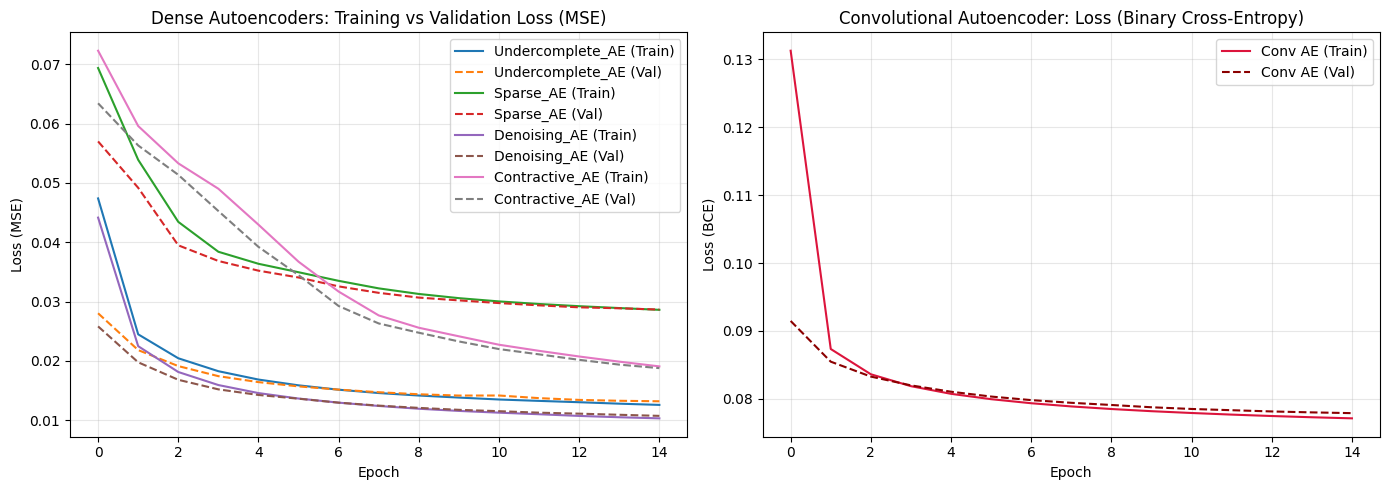

In [7]:
plt.figure(figsize=(14, 5))

# Left: Dense models (MSE Loss)
plt.subplot(1, 2, 1)
for name in ['Undercomplete_AE', 'Sparse_AE', 'Denoising_AE', 'Contractive_AE']:
    plt.plot(training_histories[name]['loss'], label=f"{name} (Train)")
    plt.plot(training_histories[name]['val_loss'], linestyle='--', label=f"{name} (Val)")
plt.title("Dense Autoencoders: Training vs Validation Loss (MSE)")
plt.xlabel("Epoch")
plt.ylabel("Loss (MSE)")
plt.legend()
plt.grid(True, alpha=0.3)

# Right: Convolutional model (BCE Loss)
plt.subplot(1, 2, 2)
plt.plot(training_histories['Convolutional_AE']['loss'], label="Conv AE (Train)", color='crimson')
plt.plot(training_histories['Convolutional_AE']['val_loss'], linestyle='--', label="Conv AE (Val)", color='darkred')
plt.title("Convolutional Autoencoder: Loss (Binary Cross-Entropy)")
plt.xlabel("Epoch")
plt.ylabel("Loss (BCE)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Step 9: Qualitative Reconstruction Gallery
Visualizing 10 test digits across Original, Noisy, and each of the 5 Autoencoders.

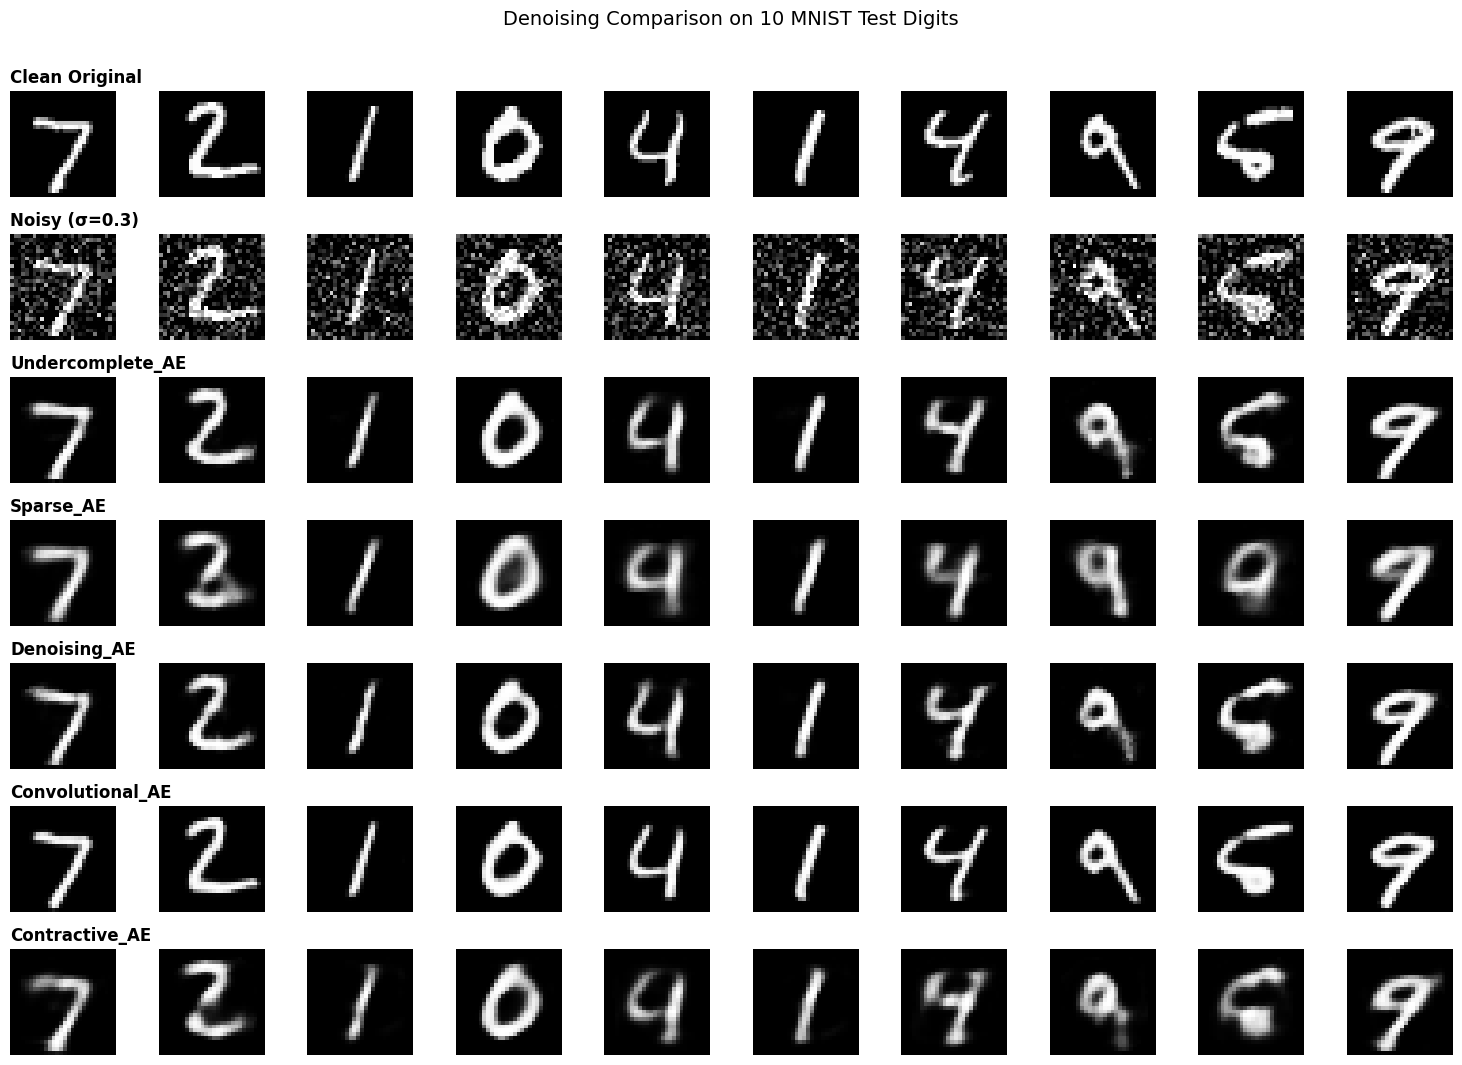

In [8]:
num_samples = 10
clean_samples = x_test_clean[:num_samples]
noisy_samples = x_test_noisy[:num_samples]

preds = {}
for name, model in models.items():
    is_conv = 'Convolutional' in name
    inp = np.expand_dims(noisy_samples, -1) if is_conv else noisy_samples.reshape(-1, 784)
    preds[name] = model.predict(inp, verbose=0).reshape(num_samples, 28, 28)

fig, axes = plt.subplots(7, num_samples, figsize=(15, 10.5))

for col in range(num_samples):
    axes[0, col].imshow(clean_samples[col], cmap='gray')
    axes[0, col].axis('off')
    if col == 0: axes[0, col].set_title('Clean Original', loc='left', fontweight='bold')

    axes[1, col].imshow(noisy_samples[col], cmap='gray')
    axes[1, col].axis('off')
    if col == 0: axes[1, col].set_title('Noisy (σ=0.3)', loc='left', fontweight='bold')

for row_idx, (m_name, p_imgs) in enumerate(preds.items(), start=2):
    for col in range(num_samples):
        axes[row_idx, col].imshow(p_imgs[col], cmap='gray')
        axes[row_idx, col].axis('off')
        if col == 0: axes[row_idx, col].set_title(m_name, loc='left', fontweight='bold')

plt.suptitle("Denoising Comparison on 10 MNIST Test Digits", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## Step 10 & 11: Quantitative Evaluation & Model Comparison Table
Evaluating MSE, MAE, PSNR (dB), and SSIM over the entire 10,000 test set.

In [9]:
def compute_metrics(clean_batch, recon_batch):
    c = clean_batch.reshape(-1, 28, 28)
    r = recon_batch.reshape(-1, 28, 28)
    mse = float(np.mean((c - r) ** 2))
    mae = float(np.mean(np.abs(c - r)))
    psnr = float(10.0 * np.log10(1.0 / mse)) if mse > 0 else float('inf')

    # SSIM averaged per image
    ssim_total = sum(ssim_fn(c[i], r[i], data_range=1.0) for i in range(len(c)))
    ssim = float(ssim_total / len(c))
    return {'MSE': mse, 'MAE': mae, 'PSNR': psnr, 'SSIM': ssim}

results_table = []
for name, model in models.items():
    is_conv = 'Convolutional' in name
    test_in = x_test_noisy_conv if is_conv else x_test_noisy_flat
    recon = model.predict(test_in, batch_size=256, verbose=0)
    m = compute_metrics(x_test_clean, recon)

    results_table.append({
        'Model': name,
        'Parameters': model.count_params(),
        'Train Time (s)': round(training_times[name], 2),
        'MSE': round(m['MSE'], 6),
        'MAE': round(m['MAE'], 6),
        'PSNR (dB)': round(m['PSNR'], 4),
        'SSIM': round(m['SSIM'], 4)
    })

df_comparison = pd.DataFrame(results_table)
display(df_comparison)

,Model,Parameters,Train Time (s),MSE,MAE,PSNR (dB),SSIM
0,Undercomplete_AE,476720,35.72,0.012938,0.039645,18.8814,0.8480
1,Sparse_AE,476720,28.91,0.027640,0.070623,15.5845,0.6817
2,Denoising_AE,484944,27.44,0.010467,0.035024,19.8020,0.8674
3,Convolutional_AE,74497,88.27,0.005041,0.022482,22.9745,0.9378
4,Contractive_AE,314544,26.40,0.018531,0.054573,17.3211,0.7657


## Step 12: Noise-Level Robustness Experiment
Evaluating the trained models on noisy test sets across $\sigma \in [0.1, 0.2, 0.3, 0.4, 0.5]$ without retraining.

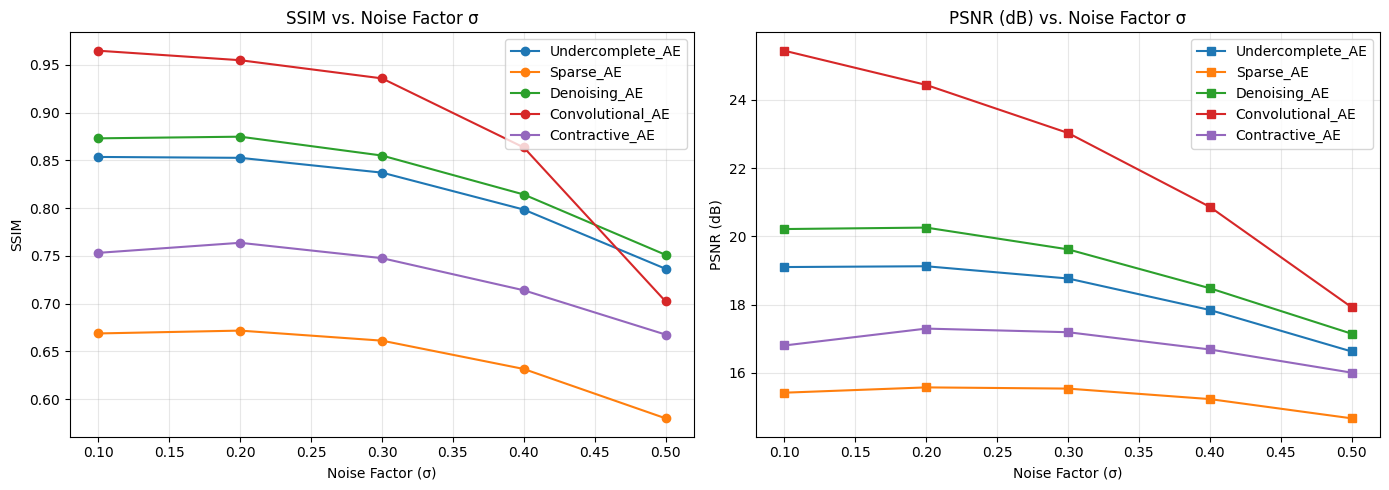

In [10]:
noise_levels = [0.1, 0.2, 0.3, 0.4, 0.5]
noise_results = []
test_subset = x_test_clean[:1000]

for sigma in noise_levels:
    noisy_sub = add_gaussian_noise(test_subset, noise_factor=sigma, seed=int(sigma*100))
    for name, model in models.items():
        is_conv = 'Convolutional' in name
        inp = np.expand_dims(noisy_sub, -1) if is_conv else noisy_sub.reshape(-1, 784)
        preds_sub = model.predict(inp, batch_size=256, verbose=0)
        m = compute_metrics(test_subset, preds_sub)
        noise_results.append({
            'Noise (σ)': sigma,
            'Model': name,
            'MSE': m['MSE'],
            'PSNR': m['PSNR'],
            'SSIM': m['SSIM']
        })

df_noise = pd.DataFrame(noise_results)

# Plot SSIM and PSNR vs Noise Factor
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
for name in models.keys():
    subset = df_noise[df_noise['Model'] == name]
    plt.plot(subset['Noise (σ)'], subset['SSIM'], marker='o', label=name)
plt.title("SSIM vs. Noise Factor σ")
plt.xlabel("Noise Factor (σ)")
plt.ylabel("SSIM")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
for name in models.keys():
    subset = df_noise[df_noise['Model'] == name]
    plt.plot(subset['Noise (σ)'], subset['PSNR'], marker='s', label=name)
plt.title("PSNR (dB) vs. Noise Factor σ")
plt.xlabel("Noise Factor (σ)")
plt.ylabel("PSNR (dB)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Step 13: Latent-Dimension Experiment
Evaluating undercomplete autoencoders across bottleneck sizes $k \in [8, 16, 32, 64, 128]$.

In [11]:
latent_dims = [8, 16, 32, 64, 128]
latent_results = []

for k in latent_dims:
    print(f"Training Undercomplete AE with latent dimension k = {k}...")
    inp = layers.Input(shape=(784,))
    x = layers.Dense(128, activation='relu')(inp)
    latent = layers.Dense(k, activation='relu')(x)
    x = layers.Dense(128, activation='relu')(latent)
    out = layers.Dense(784, activation='sigmoid')(x)
    k_model = Model(inp, out)
    k_model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss='mse')

    k_model.fit(
        x_train_noisy_flat, x_train_clean_flat,
        epochs=15, batch_size=128,
        validation_data=(x_val_noisy_flat, x_val_clean_flat),
        verbose=0
    )

    k_preds = k_model.predict(x_test_noisy_flat, batch_size=256, verbose=0)
    m = compute_metrics(x_test_clean, k_preds)
    latent_results.append({
        'Latent Dimension (k)': k,
        'Parameters': k_model.count_params(),
        'MSE': round(m['MSE'], 6),
        'PSNR (dB)': round(m['PSNR'], 4),
        'SSIM': round(m['SSIM'], 4)
    })

df_latent = pd.DataFrame(latent_results)
display(df_latent)

Training Undercomplete AE with latent dimension k = 8...
Training Undercomplete AE with latent dimension k = 16...
Training Undercomplete AE with latent dimension k = 32...
Training Undercomplete AE with latent dimension k = 64...
Training Undercomplete AE with latent dimension k = 128...


,Latent Dimension (k),Parameters,MSE,PSNR (dB),SSIM
0,8,203800,0.025793,15.8851,0.7057
1,16,205856,0.018334,17.3674,0.7852
2,32,209968,0.013787,18.6054,0.8236
3,64,218192,0.010701,19.7059,0.8475
4,128,234640,0.009455,20.2433,0.8521


## Step 14: Save Models & Deployment Export

In [12]:
os.makedirs('saved_models', exist_ok=True)

# Save the best performing Convolutional Autoencoder
models['Convolutional_AE'].save('saved_models/convolutional_ae_model.keras')
print("Convolutional Autoencoder saved successfully to 'saved_models/convolutional_ae_model.keras'!")

# Save Undercomplete Autoencoder
models['Undercomplete_AE'].save('saved_models/undercomplete_ae_model.keras')
print("Undercomplete Autoencoder saved successfully to 'saved_models/undercomplete_ae_model.keras'!")

Convolutional Autoencoder saved successfully to 'saved_models/convolutional_ae_model.keras'!
Undercomplete Autoencoder saved successfully to 'saved_models/undercomplete_ae_model.keras'!
